# Color and spatial features in BreaKHis histology images

Can a small convolutional model improve on a color-distribution baseline when image partitions keep source patient groups apart? How much does the answer depend on the distinction between image counts and patient counts? This study uses genuine BreaKHis images from the original Federal University of Parana provider.

The full archive characterizes the source collection. A predeclared 40X subset supports the model comparison, with both methods receiving the same 96-pixel center crop. The primary comparison is patient-group ROC-AUC and balanced accuracy at a fixed 0.5 threshold. Mean image probabilities provide the patient-group score. Image-level metrics are secondary because images from one source group are correlated.

This is a limited research experiment on historical, selected tumor images. It makes no diagnostic, screening, or clinical-performance claim.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, time
from collections import Counter
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, log_loss
from sklearn.calibration import calibration_curve
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT/'src'))
from histopathology.data import read_manifest, split_patients, split_record
from histopathology.features import pixels, color_features
from histopathology.experiment import run
from histopathology.evaluation import metrics
DATA=ROOT/'data/breakhis'
archive=json.loads((ROOT/'data/archive.json').read_text())
provenance=json.loads((DATA/'provenance.json').read_text())
records=pd.read_csv(DATA/'manifest.csv')
assert len(records)==7909 and records.sha256.nunique()==7909
assert records.groupby('patient_id').label.nunique().max()==1
print('Archive SHA-256:',archive['sha256'])
print('Archive bytes:',archive['bytes'],'retrieved:',archive['retrieved_at_utc'])
display(pd.Series({p:metadata.version(p) for p in ['numpy','Pillow','scikit-learn','torch','matplotlib','pandas']},name='version'))
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})


Archive SHA-256: d118014cf8a58f6d1fc4571e55efb523c932c85cfba2fb05627e455fc40bd640
Archive bytes: 4273561758 retrieved: 2026-10-31T22:21:44.129136+00:00


numpy                2.5.4
Pillow              13.0.0
scikit-learn         1.9.1
torch           2.15.0+cpu
matplotlib          3.11.2
pandas               2.3.3
Name: version, dtype: object

## Source, rights, and archive integrity

The [university provider](https://web.inf.ufpr.br/vri/databases/breast-cancer-histopathological-database-breakhis/) permits noncommercial research with citation. The page also displays a CC BY 4.0 badge; this study follows the access paragraph's noncommercial restriction and does not interpret the badge as permission for broader use. Original PNG files, source manifests with identifiers, and model weights remain local. Small transformed image panels below illustrate the research input and carry no diagnostic interpretation.

Required citation: Fabio A. Spanhol, Luiz S. Oliveira, Caroline Petitjean, and Laurent Heutte. *A Dataset for Breast Cancer Histopathological Image Classification*. IEEE Transactions on Biomedical Engineering, 63(7):1455-1462, 2016. [DOI: 10.1109/TBME.2015.2496264](https://doi.org/10.1109/TBME.2015.2496264).

The archive came from `https://www.inf.ufpr.br/vri/databases/BreaKHis_v1.tar.gz`. The complete download contains 4,273,561,758 bytes and has SHA-256 `d118014cf8a58f6d1fc4571e55efb523c932c85cfba2fb05627e455fc40bd640`. No provider checksum was available on the reviewed page; this is a local identity record. Full gzip traversal checked the trailer CRC, tar traversal completed, and the experiment ingester verified image signatures, dimensions, duplicate bytes, and provenance before fitting. The analysis below checks the retained source hashes and completed-run lineage.

The image-header audit finds 7,835 RGB images at 700 by 460 pixels and 74 at 700 by 456. Both sizes use the same crop procedure; no images are excluded for this height difference. The source does not explain it.

The provider page has inconsistent counts: its introduction says 9,109 images while its table and paper report 7,909, and one benign 40X table entry is inconsistent with its total. Counts here come from the downloaded archive, not a correction guessed from the webpage.

## Labels and conservative patient grouping

Source names encode biopsy procedure, benign or malignant class, histological subtype, year, slide identifier, magnification, and sequence. The manifest uses the literal `YEAR-SLIDE_ID` as the patient group. Sequence and magnification never define new patients.

The archive has 82 source subtype folders but 81 distinct year-and-slide identifiers. One malignant identifier appears under two subtype folders. They are merged conservatively for splitting, so a possible shared patient cannot cross partitions. This gives 24 benign and 57 malignant groups. It is not independent verification that there are 81 biological patients; the paper reports 82. The unresolved source-identity ambiguity remains a limitation, and these groups should not be silently compared with studies treating all 82 folders as independent patients.

label,benign,malignant,total
magnification,,,
40,625,1370,1995
100,644,1437,2081
200,623,1390,2013
400,588,1232,1820


Images: 7909 benign: 2480 malignant: 5429
Conservative patient groups: 81
Subtype folders: 82


,images,groups
subtype,,
A,444,4
DC,3451,38
F,1014,10
LC,626,5
MC,792,9
PC,560,6
PT,453,3
TA,569,7


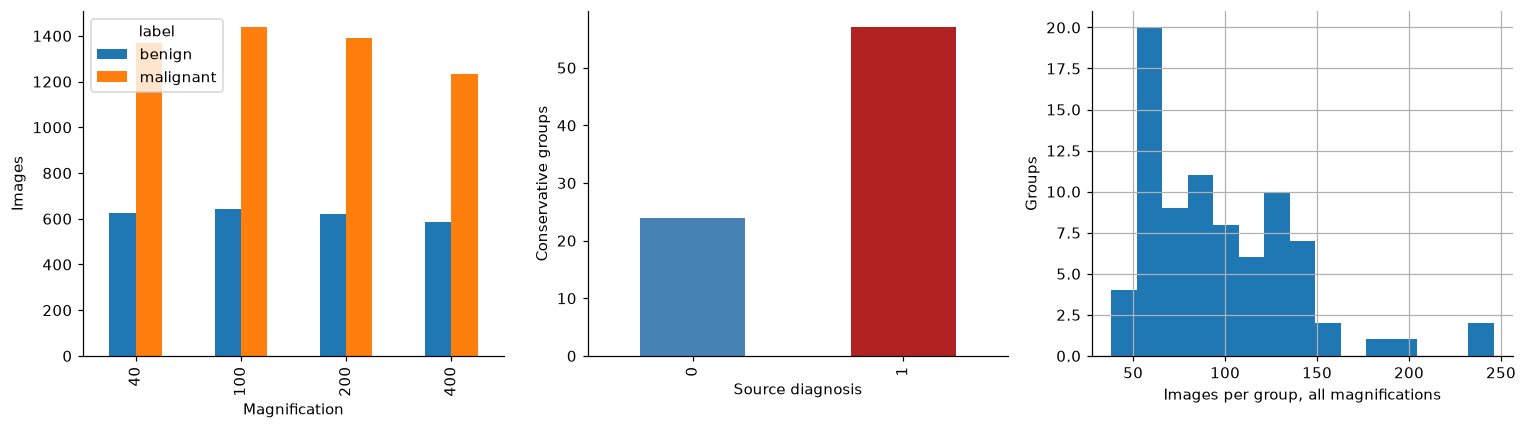

In [2]:
counts=records.groupby(['magnification','label']).size().unstack().rename(columns={0:'benign',1:'malignant'})
counts['total']=counts.sum(axis=1); display(counts)
print('Images:',len(records),'benign:',int((records.label==0).sum()),'malignant:',int((records.label==1).sum()))
print('Conservative patient groups:',records.patient_id.nunique())
print('Subtype folders:',records.image_id.str.replace(r'-(40|100|200|400)-[0-9]+\.png$','',regex=True).nunique())
display(records.groupby('subtype').agg(images=('image_id','size'),groups=('patient_id','nunique')))
fig,ax=plt.subplots(1,3,figsize=(14,4))
counts[['benign','malignant']].plot.bar(ax=ax[0]); ax[0].set(xlabel='Magnification',ylabel='Images')
records.groupby('label').patient_id.nunique().plot.bar(ax=ax[1],color=['steelblue','firebrick']); ax[1].set(xlabel='Source diagnosis',ylabel='Conservative groups')
records.groupby('patient_id').size().hist(bins=15,ax=ax[2]); ax[2].set(xlabel='Images per group, all magnifications',ylabel='Groups')
plt.tight_layout();plt.show()


## Image appearance and magnification

The panel shows deterministic examples by source diagnosis and magnification. It uses the same center-crop and resize procedure as the models. Differences in field of view and staining can be visible, but labels come from the provider; this report does not infer a diagnosis from a visual impression. The experiments use only 40X images, avoiding a pooled-magnification comparison in which scale could become a shortcut.

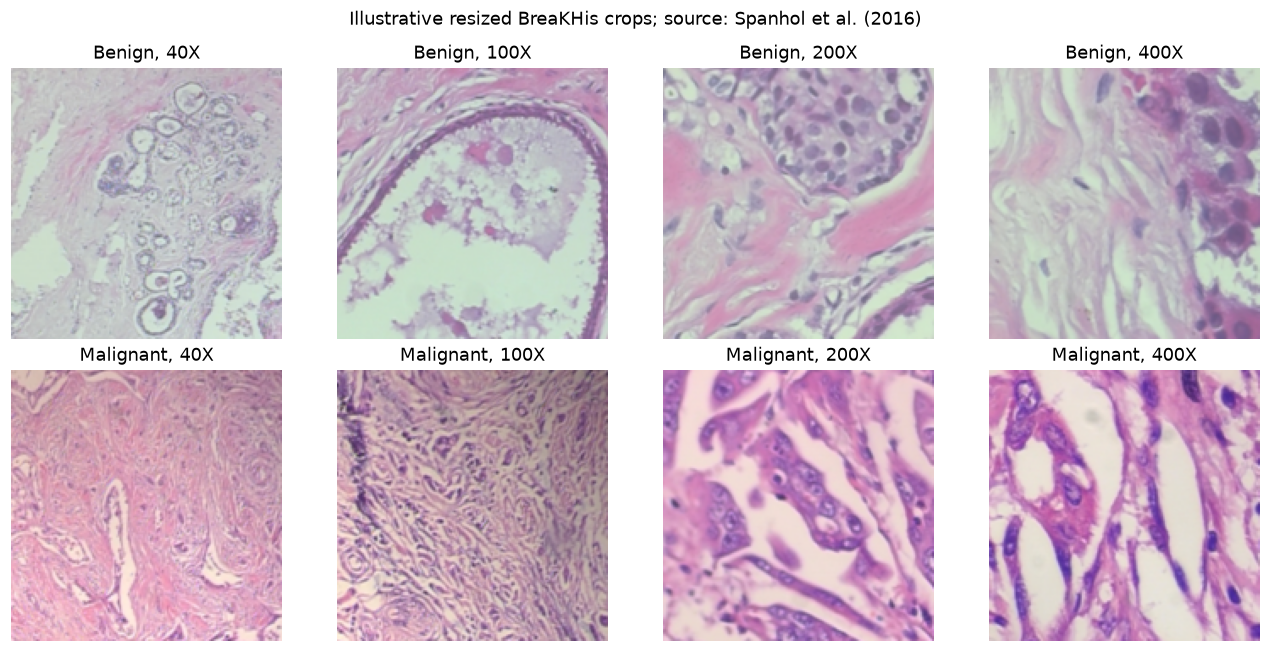

In [3]:
from histopathology.data import Sample
rows=records.sort_values('image_id')
fig,axes=plt.subplots(2,4,figsize=(12,6))
for label in [0,1]:
 for j,mag in enumerate([40,100,200,400]):
  row=rows[(rows.label==label)&(rows.magnification==mag)].iloc[0]
  sample=Sample(row.image_id,row.patient_id,row.path,int(row.label),row.sha256)
  axes[label,j].imshow(pixels(DATA,sample,160));axes[label,j].axis('off')
  axes[label,j].set_title(f"{'Benign' if label==0 else 'Malignant'}, {mag}X")
fig.suptitle('Illustrative resized BreaKHis crops; source: Spanhol et al. (2016)')
plt.tight_layout();plt.show()


## Preprocessing and experimental design

Both methods convert source RGB images to floating-point values in [0,1], retain aspect ratio through a square center crop, and resize to 96 by 96 pixels. On a 700 by 460 image the square crop removes lateral tissue, and downsampling loses cellular detail. No stain normalization, pretrained weights, segmentation, clinical covariates, or patient identifiers enter the predictors.

Patients are stratified by diagnosis using seed 42. Per-class integer rounding assigns at least one patient group to validation and test; the resulting proportions are approximate. All images from a year-and-slide group remain together. The 40X split is fixed before model fitting. Exact file duplicates are rejected globally, but transformed duplicates and undocumented aliases cannot be ruled out.

The color baseline uses 16-bin histograms for each RGB channel plus RGB means and standard deviations (54 features), followed by weighted scaling and logistic regression. Each training group has equal total weight. The small CNN has three convolutional blocks and a global average pooling head. Its patient-balanced sampler equalizes group contributions in expectation. Training augmentation uses flips and quarter-turn rotations only. Validation and test receive no augmentation.

,images,groups,benign_groups,malignant_groups,malignant_image_fraction
train,1269.0,51.0,16.0,35.0,0.679275
validation,377.0,15.0,4.0,11.0,0.718833
test,349.0,15.0,4.0,11.0,0.679083


Original dimension counts: {(700, 460): 7835, (700, 456): 74} color modes: {'RGB': 7909}


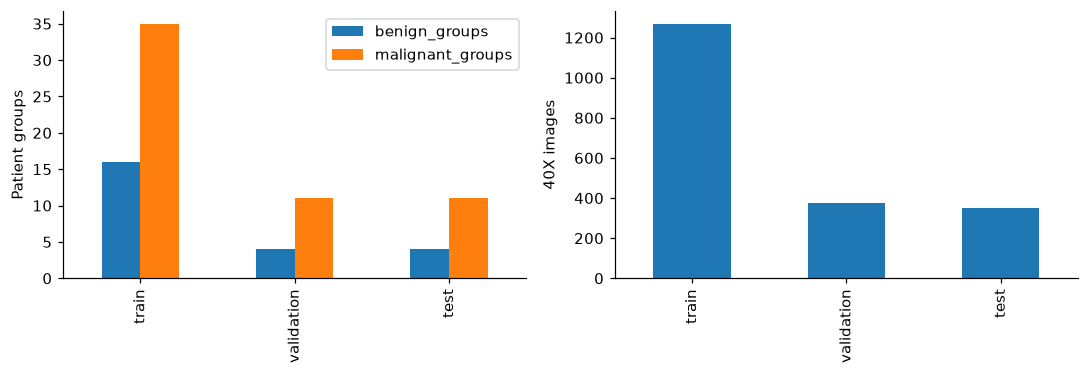

In [4]:
records[records.magnification==40].to_csv(DATA/'manifest_40x.csv',index=False)
samples,info=read_manifest(DATA/'manifest_40x.csv',DATA,DATA/'provenance.json')
splits=split_patients(samples,42,.2,.2)
group_sets={k:{s.patient_id for s in v} for k,v in splits.items()}
assert not group_sets['train'] & group_sets['validation']
assert not group_sets['train'] & group_sets['test']
assert not group_sets['validation'] & group_sets['test']
summary=pd.DataFrame({name:{'images':len(part),'groups':len({s.patient_id for s in part}),
 'benign_groups':len({s.patient_id for s in part if s.label==0}),
 'malignant_groups':len({s.patient_id for s in part if s.label==1}),
 'malignant_image_fraction':np.mean([s.label for s in part])} for name,part in splits.items()}).T
display(summary)
dimensions=Counter();modes=Counter()
for row in records.itertuples():
 with Image.open(DATA/row.path) as image: dimensions[image.size]+=1;modes[image.mode]+=1
print('Original dimension counts:',dict(dimensions),'color modes:',dict(modes))
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
summary[['benign_groups','malignant_groups']].plot.bar(ax=ax[0]);ax[0].set_ylabel('Patient groups')
summary.images.plot.bar(ax=ax[1]);ax[1].set_ylabel('40X images')
plt.tight_layout();plt.show()


## Training color features

Color summaries characterize this input representation, not tissue biology. They can expose staining or acquisition differences that a classifier might exploit. The training distribution is examined before validation and test comparisons. Histograms and mean/std summaries do not preserve spatial arrangement, so they offer a useful reference for what the CNN adds.

,count,mean,std,min,25%,50%,75%,max
R_mean,1269.0,0.806820,0.062222,0.612987,0.760333,0.804728,0.848642,0.982015
G_mean,1269.0,0.665899,0.087762,0.257302,0.611779,0.679213,0.720082,0.887328
B_mean,1269.0,0.778196,0.057184,0.619557,0.738274,0.771697,0.811081,0.965285
R_std,1269.0,0.062599,0.023109,0.018025,0.045652,0.058278,0.076372,0.160880
G_std,1269.0,0.092018,0.034720,0.025824,0.066949,0.087002,0.110021,0.280542
B_std,1269.0,0.060942,0.023390,0.019935,0.043256,0.057200,0.073765,0.175620


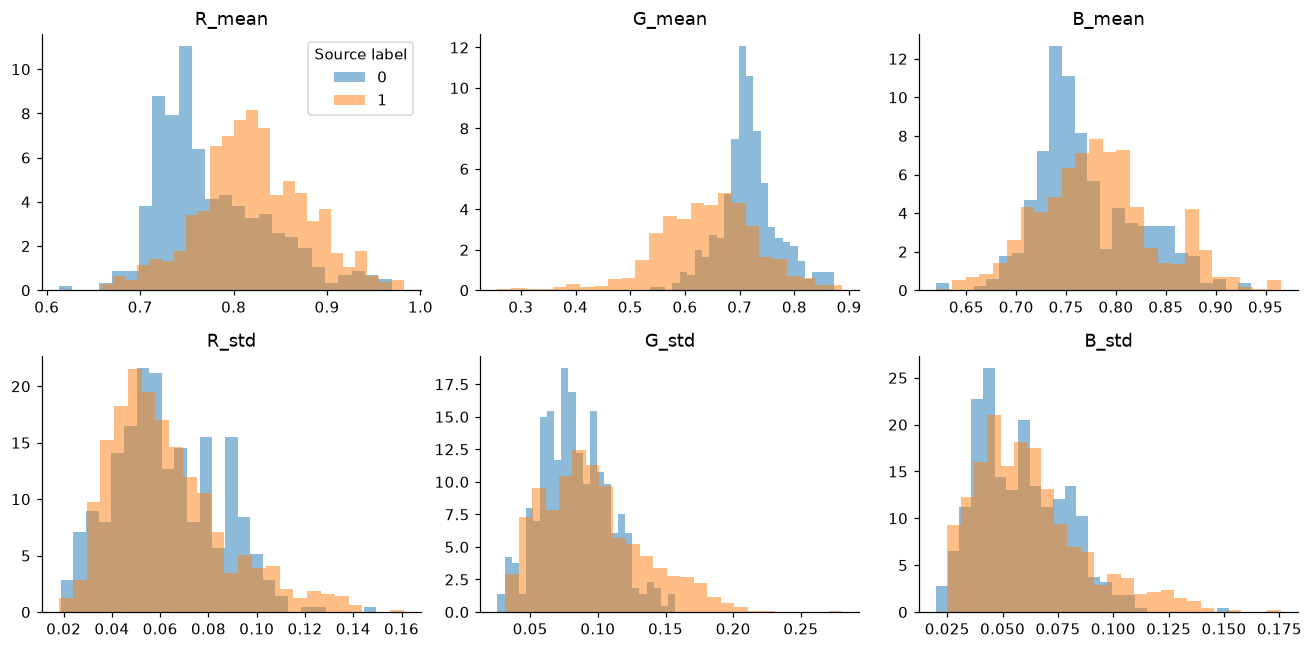

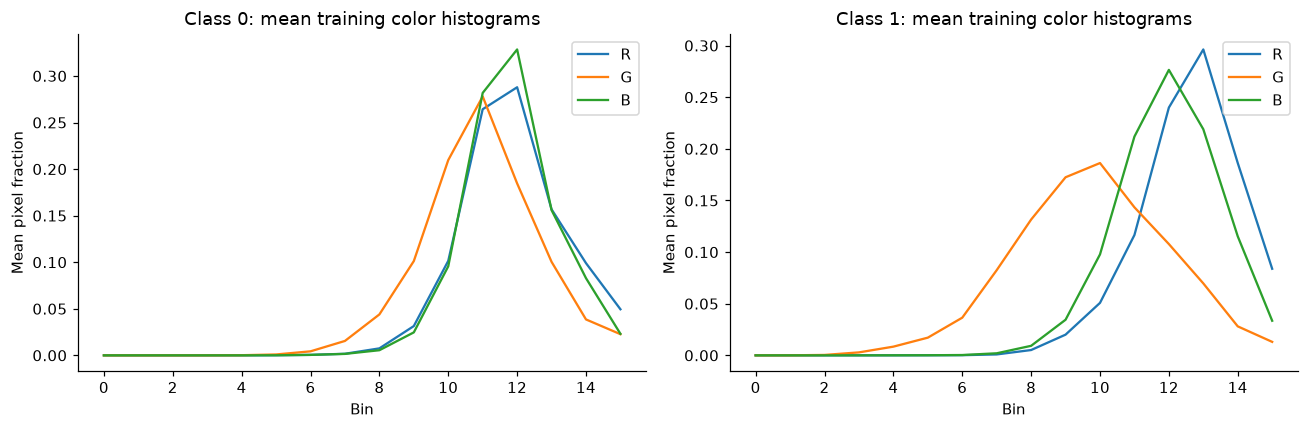

In [5]:
feature_names=[f'{c}_bin_{b}' for c in ['R','G','B'] for b in range(16)]+[f'{c}_mean' for c in ['R','G','B']]+[f'{c}_std' for c in ['R','G','B']]
xtrain=color_features(DATA,splits['train'],96).astype(float)
ytrain=np.array([s.label for s in splits['train']])
features=pd.DataFrame(xtrain,columns=feature_names)
display(features.iloc[:,-6:].describe().T)
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,name in zip(axes.flat,feature_names[-6:]):
 for label in [0,1]:ax.hist(features.loc[ytrain==label,name],bins=25,density=True,alpha=.5,label=str(label))
 ax.set_title(name)
axes.flat[0].legend(title='Source label');plt.tight_layout();plt.show()
fig,ax=plt.subplots(1,2,figsize=(12,4))
for label in [0,1]:
 mean=xtrain[ytrain==label,:48].mean(axis=0).reshape(3,16)
 for c,channel in enumerate(['R','G','B']):ax[label].plot(range(16),mean[c],label=channel)
 ax[label].set(title=f'Class {label}: mean training color histograms',xlabel='Bin',ylabel='Mean pixel fraction');ax[label].legend()
plt.tight_layout();plt.show()


## Controlled CPU training

The experiment uses a fixed ten-epoch CNN budget, batch size 32, AdamW learning rate 0.001, weight decay 0.0001, four CPU threads, and deterministic PyTorch algorithms. The checkpoint with the lowest validation patient-group log loss is retained. The 0.5 decision cutoff is fixed for both models and never tuned on test. There is no search over seeds, magnifications, or architectures.

The saved training histories and predictions come from completed runs with the configuration above. Input hashes and patient membership are checked before analysis; missing runs are executed with the same protocol.

In [6]:
config={'image_size':96,'epochs':10,'batch_size':32,'threads':4,'bootstrap_replicates':1000}
runs={}; histories={}; predictions={}; results={}; environments={}
for kind in ['baseline','cnn']:
 out=ROOT/'artifacts'/f'breakhis40x-{kind}'
 if not out.exists():run(DATA/'manifest_40x.csv',DATA,DATA/'provenance.json',out,config,kind)
 assert json.loads((out/'status.json').read_text())['status']=='completed'
 env=json.loads((out/'environment.json').read_text())
 for filename,expected in env['source_sha256'].items():
  assert hashlib.sha256((ROOT/'src/histopathology'/filename).read_bytes()).hexdigest()==expected
 assert hashlib.sha256((DATA/'manifest_40x.csv').read_bytes()).hexdigest()==env['manifest_sha256']
 assert json.loads((out/'splits.json').read_text())==split_record(splits)
 assert json.loads((out/'provenance.json').read_text())==provenance
 saved_config=json.loads((out/'config.json').read_text())
 for key,value in config.items():assert saved_config[key]==value
 assert saved_config['seed']==42 and saved_config['threshold']==.5
 runs[kind]=out;environments[kind]=env
 histories[kind]=json.loads((out/'history.json').read_text())
 results[kind]=json.loads((out/'metrics.json').read_text())
 predictions[kind]={name:json.loads((out/f'{name}_predictions.json').read_text()) for name in ['validation','test']}
 print(kind,'completed at',env['created_at'],'source files verified:',len(env['source_sha256']))
print('CPU:',platform.processor(),'Python:',platform.python_version())


baseline completed at 2026-10-31T22:33:26.609344+00:00 source files verified: 10
cnn completed at 2026-10-31T22:34:08.399965+00:00 source files verified: 10
CPU: Intel64 Family 6 Model 191 Stepping 2, GenuineIntel Python: 3.12.10


## Learning trajectory and validation comparison

Training loss is the mean over patient-balanced sampled image batches. Validation loss averages each group's image scores first, so it measures a different unit. A separation between those curves can reflect sampling, augmentation, or generalization error; it should not be interpreted as a direct loss gap on identical observations. Only validation patient log loss selects a CNN epoch.

The baseline and CNN are retained as predeclared comparisons. No model is promoted using test outcomes. The constant training patient-prevalence predictor provides a no-information reference for probability loss and ranking.

,epoch,training_batch_mean_loss,validation_patient_log_loss
0,1,0.625211,0.596812
1,2,0.523904,0.675329
2,3,0.476384,0.838717
3,4,0.471366,0.817987
4,5,0.459922,0.926690
5,6,0.420179,0.905855
6,7,0.436234,0.811628
7,8,0.433783,0.849104
8,9,0.433984,0.842094
9,10,0.431988,0.881642


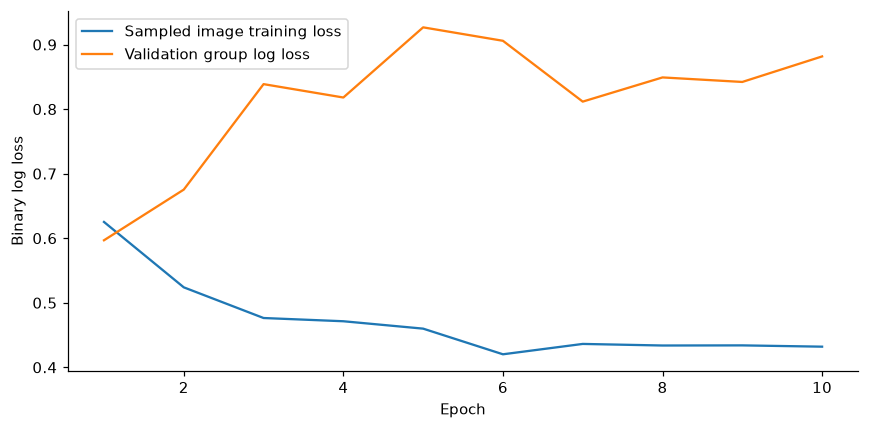

,n,roc_auc,balanced_accuracy,sensitivity,specificity,brier,log_loss
baseline,15,0.568182,0.704545,0.909091,0.5,0.197985,0.846086
cnn,15,0.5,0.5,1.0,0.0,0.202371,0.596812


Chosen CNN epoch: 1


In [7]:
history=pd.DataFrame(histories['cnn']);display(history)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(history.epoch,history.training_batch_mean_loss,label='Sampled image training loss')
ax.plot(history.epoch,history.validation_patient_log_loss,label='Validation group log loss')
ax.set(xlabel='Epoch',ylabel='Binary log loss');ax.legend();plt.tight_layout();plt.show()
validation=pd.DataFrame({k:v['validation']['patient'] for k,v in results.items()}).T
display(validation[['n','roc_auc','balanced_accuracy','sensitivity','specificity','brier','log_loss']])
print('Chosen CNN epoch:',int(history.loc[history.validation_patient_log_loss.idxmin(),'epoch']))


## Held-out image and patient-group performance

Patient-group scores are means of the frozen model's image probabilities. Group aggregation can reduce image-level noise, but it does not create more independent subjects. The test split is small, so report confusion counts alongside ROC-AUC and balanced accuracy. The reported intervals resample patient groups rather than individual images and skip resamples with a single outcome class.

,n,roc_auc,average_precision,balanced_accuracy,sensitivity,specificity,brier,roc_auc_bootstrap_95_interval,bootstrap_valid_replicates
baseline,15,0.954545,0.98416,0.75,1.0,0.5,0.088731,"[0.7831349206349206, 1.0]",988
cnn,15,0.977273,0.992424,0.5,1.0,0.0,0.169497,"[0.8461538461538461, 1.0]",988


,n,roc_auc,balanced_accuracy,sensitivity,specificity,confusion_matrix
baseline,349,0.94786,0.718995,0.991561,0.446429,"[[50, 62], [2, 235]]"
cnn,349,0.936709,0.5,1.0,0.0,"[[0, 112], [0, 237]]"


average_precision                                 0.662446
balanced_accuracy                                      0.5
bootstrap_valid_replicates                             988
brier                                              0.19777
confusion_matrix                         [[0, 4], [0, 11]]
f1                                                0.846154
log_loss                                          0.585213
n                                                       15
roc_auc                                           0.261364
roc_auc_bootstrap_95_interval    [0.0, 0.5972222222222222]
sensitivity                                            1.0
specificity                                            0.0
Name: constant training-group prior, dtype: object

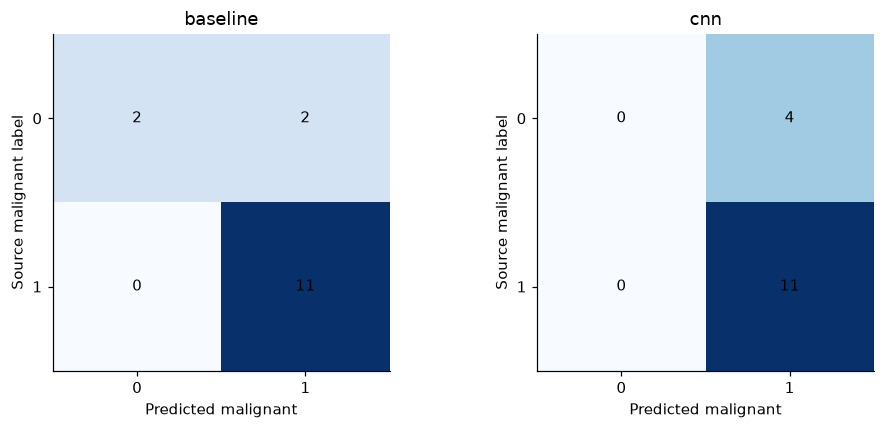

In [8]:
test_table=pd.DataFrame({k:v['test']['patient'] for k,v in results.items()}).T
image_table=pd.DataFrame({k:v['test']['image'] for k,v in results.items()}).T
display(test_table[['n','roc_auc','average_precision','balanced_accuracy','sensitivity','specificity','brier','roc_auc_bootstrap_95_interval','bootstrap_valid_replicates']])
display(image_table[['n','roc_auc','balanced_accuracy','sensitivity','specificity','confusion_matrix']])
prior=results['baseline']['test_constant_patient_prior']['patient'];display(pd.Series(prior,name='constant training-group prior'))
fig,axes=plt.subplots(1,2,figsize=(9,4))
for ax,kind in zip(axes,['baseline','cnn']):
 cm=np.array(results[kind]['test']['patient']['confusion_matrix']);ax.imshow(cm,cmap='Blues')
 for (i,j),value in np.ndenumerate(cm):ax.text(j,i,str(value),ha='center',va='center')
 ax.set(title=kind,xticks=[0,1],yticks=[0,1],xlabel='Predicted malignant',ylabel='Source malignant label')
plt.tight_layout();plt.show()


## Ranking and probability diagnostics

ROC and precision-recall curves operate on the same small group cohort. Average precision depends on the malignant fraction and is not a direct measure of clinical utility. Calibration points use at most five quantile bins, with few groups per bin. The curves and probability losses characterize this experiment; they cannot establish calibration at a new laboratory.

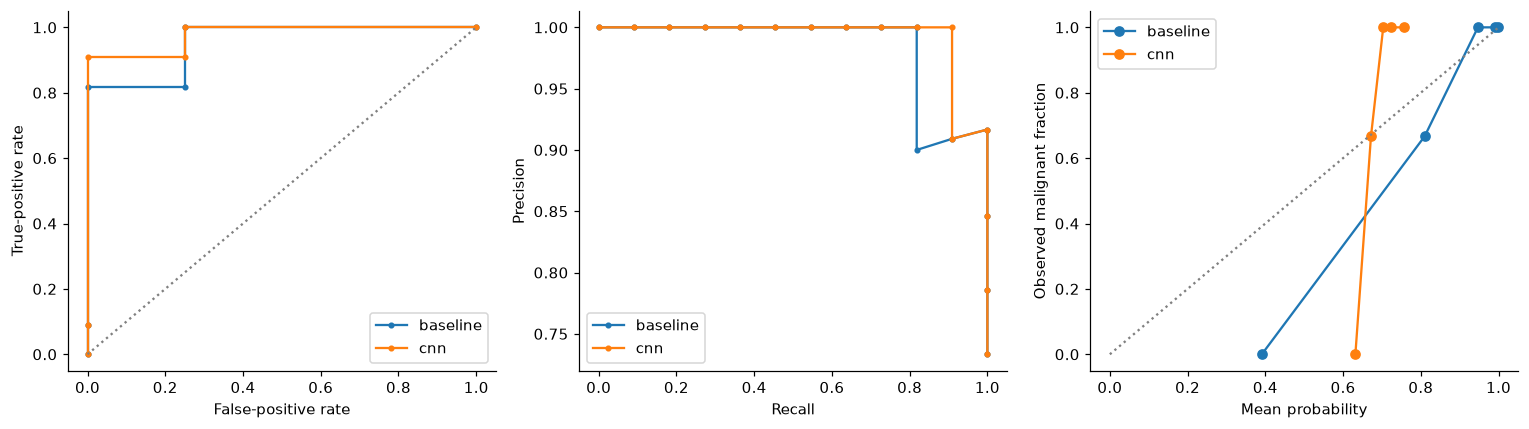

In [9]:
def grouped(rows):
 f=pd.DataFrame(rows);g=f.groupby('patient_id',sort=True).agg(label=('label','first'),probability=('probability','mean'),images=('image_id','size'))
 return g
patient={k:grouped(predictions[k]['test']) for k in predictions}
assert patient['baseline'].index.equals(patient['cnn'].index)
fig,ax=plt.subplots(1,3,figsize=(14,4))
for kind,g in patient.items():
 fpr,tpr,_=roc_curve(g.label,g.probability);ax[0].plot(fpr,tpr,marker='.',label=kind)
 p,r,_=precision_recall_curve(g.label,g.probability);ax[1].plot(r,p,marker='.',label=kind)
 observed,predicted=calibration_curve(g.label,g.probability,n_bins=5,strategy='quantile');ax[2].plot(predicted,observed,marker='o',label=kind)
ax[0].plot([0,1],[0,1],ls=':',color='gray');ax[0].set(xlabel='False-positive rate',ylabel='True-positive rate')
ax[1].set(xlabel='Recall',ylabel='Precision')
ax[2].plot([0,1],[0,1],ls=':',color='gray');ax[2].set(xlabel='Mean probability',ylabel='Observed malignant fraction')
for a in ax:a.legend()
plt.tight_layout();plt.show()


## Paired uncertainty and agreement

A paired bootstrap resamples the same test patient groups for both methods and computes CNN-minus-baseline differences. This keeps within-group images together through their mean scores. One thousand replicates use seed 2026; single-class samples are counted and skipped. Percentile intervals condition on one split, fitted models, and the fixed cutoff. They exclude retraining, checkpoint-selection, source identity, laboratory, and population uncertainty. With only a few benign test groups, their endpoints are unstable.

,estimate,lower_95,upper_95
roc_auc,0.022727,-0.071429,0.162054
balanced_accuracy,-0.250000,-0.500000,0.000000
brier,0.080767,0.021795,0.138412


Completed paired resamples: 992 single-class skips: 8


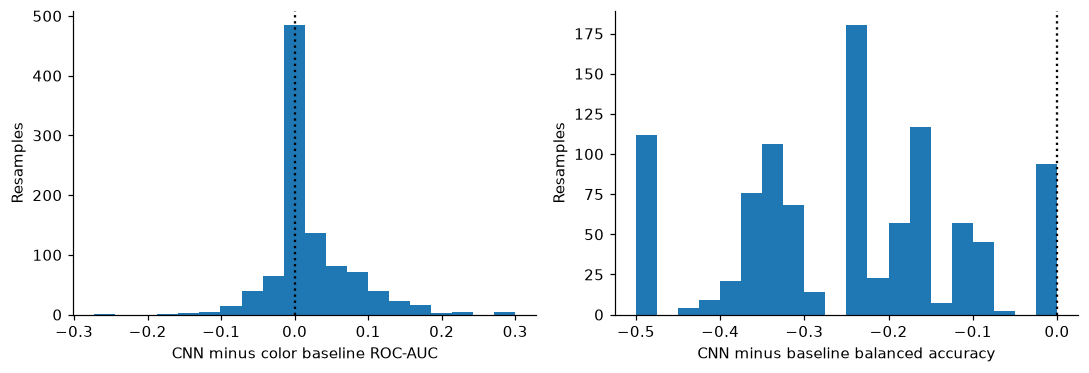

CNN predicts malignant,True
Baseline predicts malignant,
False,2
True,13


In [10]:
a=patient['baseline'];b=patient['cnn'];y=a.label.to_numpy();pa=a.probability.to_numpy();pb=b.probability.to_numpy()
rng=np.random.default_rng(2026);draws=[];skipped=0
for _ in range(1000):
 ids=rng.integers(0,len(y),len(y))
 if len(np.unique(y[ids]))<2:skipped+=1;continue
 ma=metrics(y[ids],pa[ids]);mb=metrics(y[ids],pb[ids])
 draws.append({k:mb[k]-ma[k] for k in ['roc_auc','balanced_accuracy','brier']})
draws=pd.DataFrame(draws)
paired=pd.DataFrame({'estimate':{k:results['cnn']['test']['patient'][k]-results['baseline']['test']['patient'][k] for k in draws.columns},'lower_95':draws.quantile(.025),'upper_95':draws.quantile(.975)})
display(paired);print('Completed paired resamples:',len(draws),'single-class skips:',skipped)
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
ax[0].hist(draws.roc_auc,bins=20);ax[0].axvline(0,color='black',ls=':');ax[0].set(xlabel='CNN minus color baseline ROC-AUC',ylabel='Resamples')
ax[1].hist(draws.balanced_accuracy,bins=20);ax[1].axvline(0,color='black',ls=':');ax[1].set(xlabel='CNN minus baseline balanced accuracy',ylabel='Resamples')
plt.tight_layout();plt.show()
agreement=pd.crosstab(pa>=.5,pb>=.5);agreement.index.name='Baseline predicts malignant';agreement.columns.name='CNN predicts malignant';display(agreement)


## Aggregate error profiles and a limited brightness stress test

Error analysis groups test images by source subtype and keeps individual predictions and identifiers local. Each row reports image and group counts so a subtype represented by very few groups is not mistaken for independent evidence. These summaries are descriptive after test evaluation.

A predeclared 0.8 and 1.2 brightness multiplier probes sensitivity to a simple pixel perturbation with both models frozen. It is neither a stain-transfer experiment nor external laboratory validation. Clipping and changed color histograms can affect the baseline and CNN differently.

,model,subtype,images,groups,errors,error_fraction
0,baseline,A,64,2,50,0.781250
1,baseline,DC,206,9,0,0.000000
2,baseline,F,48,2,12,0.250000
3,baseline,MC,31,2,2,0.064516
4,cnn,A,64,2,64,1.000000
5,cnn,DC,206,9,0,0.000000
6,cnn,F,48,2,48,1.000000
7,cnn,MC,31,2,0,0.000000


,model,brightness,roc_auc,balanced_accuracy,brier
0,baseline,0.8,0.863636,0.875000,0.076479
1,baseline,1.2,0.886364,0.454545,0.169096
2,cnn,0.8,0.977273,0.500000,0.178763
3,cnn,1.2,0.954545,0.500000,0.169698


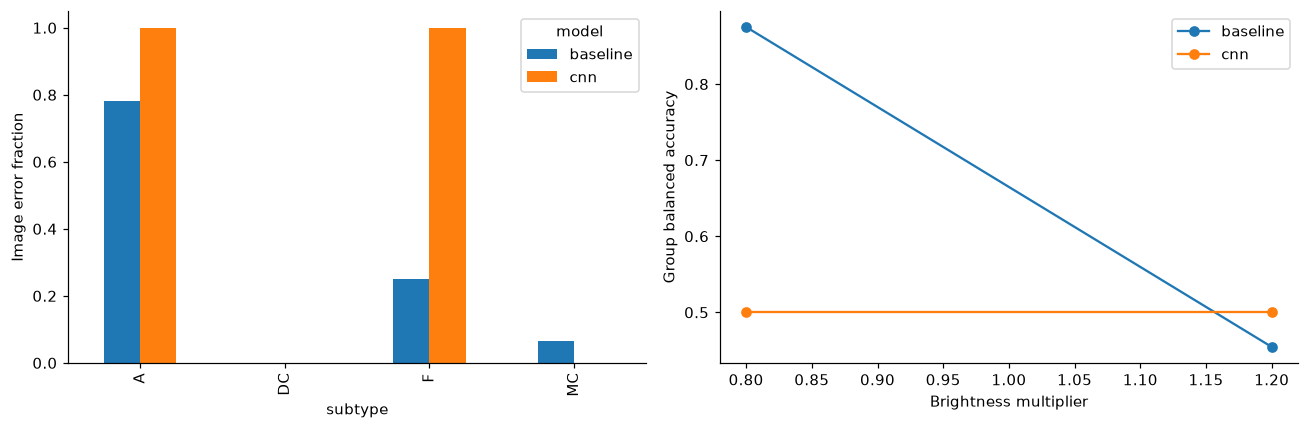

In [11]:
error_rows=[]
lookup=records.set_index('image_id')
for kind in ['baseline','cnn']:
 f=pd.DataFrame(predictions[kind]['test']);f['subtype']=f.image_id.map(lookup.subtype);f['wrong']=(f.probability>=.5)!=f.label
 for subtype,g in f.groupby('subtype'):
  error_rows.append({'model':kind,'subtype':subtype,'images':len(g),'groups':g.patient_id.nunique(),'errors':int(g.wrong.sum()),'error_fraction':g.wrong.mean()})
errors=pd.DataFrame(error_rows);display(errors)
stress=[]
for kind in ['baseline','cnn']:
 for factor,value in results[kind]['test_brightness_stress'].items():
  stress.append({'model':kind,'brightness':float(factor),**{key:value['patient'][key] for key in ['roc_auc','balanced_accuracy','brier']}})
stress=pd.DataFrame(stress);display(stress)
fig,ax=plt.subplots(1,2,figsize=(12,4))
errors.pivot(index='subtype',columns='model',values='error_fraction').plot.bar(ax=ax[0]);ax[0].set_ylabel('Image error fraction')
for kind in ['baseline','cnn']:
 part=stress[stress.model==kind];ax[1].plot(part.brightness,part.balanced_accuracy,marker='o',label=kind)
ax[1].set(xlabel='Brightness multiplier',ylabel='Group balanced accuracy');ax[1].legend()
plt.tight_layout();plt.show()


## Findings and limits

The 40X subset contains 1,995 images. Training, validation, and test have 1,269 / 377 / 349 images from 51 / 15 / 15 conservative patient groups. Each held-out partition has only four benign and eleven malignant groups. These counts make the effective sample much smaller than the image count suggests.

The CNN checkpoint comes from epoch 1, with validation patient log loss 0.596812. Later validation losses worsen while sampled training loss generally falls. The baseline's validation ROC-AUC is 0.568182 and the CNN's is 0.500000. Their much higher test AUCs show substantial partition variation; a single favorable test ranking does not establish stable generalization.

On test, baseline group ROC-AUC is 0.954545 and CNN group ROC-AUC is 0.977273. The paired CNN-minus-baseline difference is 0.022727, with a conditional 95% bootstrap interval of -0.071429 to 0.162054. That interval includes zero and does not establish an improvement. At the fixed 0.5 cutoff, the baseline correctly labels two of four benign groups and all eleven malignant groups. The CNN labels all fifteen groups malignant. Balanced accuracy is 0.750000 for the baseline and 0.500000 for the CNN. High ranking discrimination therefore coexists with an unhelpful CNN operating point.

The CNN's patient-group Brier loss is also worse: 0.169497 versus 0.088731. The paired difference is 0.080767, with interval 0.021795 to 0.138412; positive values favor the color baseline. These are conditional comparisons of the completed experiments, not clinical probability assessments.

The color baseline is sensitive to the simple brightness change: group balanced accuracy is 0.875000 at multiplier 0.8 and 0.454545 at 1.2, compared with 0.750000 without perturbation. This is evidence about a specific pixel operation, not cross-laboratory stain robustness.

The next cell reports the completed comparison from the retained experiment outputs. Test performance is conditional on this split and conservative grouping rule. The validation-to-test change should be assessed alongside the small number of independent groups, rather than attributed to a single biological explanation.

Several limitations dominate interpretation. Both methods lose tissue outside the center crop and fine detail after resizing. The CNN has a short CPU training budget, no pretrained representation, and one seed. The data comes from one source collection; there is no site-disjoint or prospective validation. Original patient identities and the repeated source identifier cannot be resolved independently. Some source subtypes have few groups, and no fairness, consent re-audit, or clinical decision analysis is attempted.

A useful extension would predeclare additional patient splits, resolve source identifier aliases with the provider, examine larger or multi-crop images, and evaluate a separately governed external collection. None of those experiments is claimed here.

In [12]:
for kind in ['baseline','cnn']:
 r=results[kind]['test']['patient']
 print(f"{kind}: group ROC-AUC {r['roc_auc']:.6f}, balanced accuracy {r['balanced_accuracy']:.6f}, Brier {r['brier']:.6f}; confusion {r['confusion_matrix']}")
 print('Conditional patient-bootstrap ROC-AUC interval:',r['roc_auc_bootstrap_95_interval'])
print('Paired CNN-minus-baseline ROC-AUC interval:',paired.loc['roc_auc',['lower_95','upper_95']].to_list())
aggregate={'source_archive':archive,'groups':81,'source_folders':82,'images':7909,'study_magnification':40,
 'split_counts':summary.to_dict(orient='index'),'original_dimensions':{f'{w}x{h}':count for (w,h),count in dimensions.items()},'config':config,'seed':42,
 'models':{kind:{name:{level:results[kind][name][level] for level in ['image','patient']} for name in ['validation','test']} for kind in ['baseline','cnn']},
 'training_history':histories['cnn'],'paired_intervals':paired.to_dict(),'paired_valid_replicates':len(draws),'paired_skipped':skipped,
 'brightness_stress':stress.to_dict(orient='records'),
 'environment':{'python':platform.python_version(),'packages':{p:metadata.version(p) for p in ['numpy','Pillow','scikit-learn','torch','matplotlib','pandas']},'threads':4},'source_sha256':environments['cnn']['source_sha256']}
out=ROOT/'artifacts/research';out.mkdir(parents=True,exist_ok=True)
(out/'aggregate_results.json').write_text(json.dumps(aggregate,indent=2,allow_nan=False),encoding='utf-8')


baseline: group ROC-AUC 0.954545, balanced accuracy 0.750000, Brier 0.088731; confusion [[2, 2], [0, 11]]
Conditional patient-bootstrap ROC-AUC interval: [0.7831349206349206, 1.0]
cnn: group ROC-AUC 0.977273, balanced accuracy 0.500000, Brier 0.169497; confusion [[0, 4], [0, 11]]
Conditional patient-bootstrap ROC-AUC interval: [0.8461538461538461, 1.0]
Paired CNN-minus-baseline ROC-AUC interval: [-0.07142857142857151, 0.16205357142857163]


9991

## Reproducibility

The source archive, original PNGs, full identifier manifests, predictions, and model checkpoints remain in ignored local directories. The report retains aggregate tables, illustrative resized crops, and figures from completed experiments. The university citation above applies to the image examples as well as the analysis.

From a clean research kernel, execute all cells in order with the project directory as the working directory. The notebook verifies local completed-run lineage before using results and can run missing experiments through the maintained framework. The separate `histopathology.breakhis` adapter prepares original source filenames and checks complete archive traversal. Contract tests cover grouping, archive paths and corruption, patient separation, preprocessing, evaluation, and numerical reconstruction of the baseline. Engineering modules support the study; they are not evidence of clinical validity.